## JORGE ANDRÉS CEBALLOS CRUZ

## 1054867490

In [7]:
import os
import kagglehub
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

# Descarga automáticamente el dataset de Kaggle
path = kagglehub.dataset_download("camnugent/california-housing-prices")

# Carga el archivo en un DataFrame
df = pd.read_csv(os.path.join(path, "housing.csv"))


In [5]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


## 1. Tipos de Datos y Preprocesamiento


## 1.1 Identificación

**Enunciado:** Carga el dataset y clasifica las columnas en Nominales, Ordinales, Discretas o Continuas. ¿En qué categoría entra la variable `ocean_proximity`?

**Respuesta:**

La variable `ocean_proximity` se clasifica como **Categórica Ordinal**. Sus valores están representados como etiquetas de texto que, según esta interpretación, guardan una relación de jerarquía y distancia geográfica respecto al mar, lo que implica una graduación ordenada entre las categorías.

### Clasificación de las 10 columnas

- **`longitude`**: **Numérica Continua.** Coordenada geográfica cuantitativa con decimales.
- **`latitude`**: **Numérica Continua.** Coordenada geográfica cuantitativa con decimales.
- **`housing_median_age`**: **Numérica Discreta.** Conteo entero de años de antigüedad.
- **`total_rooms`**: **Numérica Discreta.** Conteo entero de habitaciones totales.
- **`total_bedrooms`**: **Numérica Discreta.** Conteo entero de dormitorios totales.
- **`population`**: **Numérica Discreta.** Conteo entero de habitantes en la zona.
- **`households`**: **Numérica Discreta.** Conteo entero de hogares o familias.
- **`median_income`**: **Numérica Continua.** Escala continua del ingreso medio, expresada en decenas de miles de dólares.
- **`median_house_value`**: **Numérica Continua.** Valor cuantitativo continuo del precio de la vivienda.
- **`ocean_proximity`**: **Categórica Ordinal.** Variable cualitativa que, según la clasificación propuesta, representa categorías relacionadas con la proximidad al mar.



## 1.2 Técnica de encoding

**Enunciado:** ¿Qué técnica de encoding deberías usar si se asume un orden de cercanía al mar?

**Respuesta:**

Se debe utilizar **Label Encoding**.

**Justificación:**

Esta técnica convierte las etiquetas de texto en números enteros conservando el orden establecido entre las categorías. Al asignar valores numéricos secuenciales según la cercanía al mar, por ejemplo, `INLAND = 0`, `<1H OCEAN = 1`, `NEAR BAY = 2`, `NEAR OCEAN = 3` e `ISLAND = 4`, se representa una relación ordinal entre las categorías para el modelo de Machine Learning.


In [ ]:
orden_cercania = [["INLAND", "<1H OCEAN", "NEAR BAY", "NEAR OCEAN", "ISLAND"]]

# Creamos e instanciamos el encoder
nuevaColumna = OrdinalEncoder(categories=orden_cercania)

# Creamos la NUEVA columna sin destruir la original
df["ocean_proximity_encoded"] = nuevaColumna.fit_transform(df[["ocean_proximity"]])

In [9]:
df[["ocean_proximity", "ocean_proximity_encoded"]]

,ocean_proximity,ocean_proximity_encoded
0,NEAR BAY,2.0
1,NEAR BAY,2.0
2,NEAR BAY,2.0
3,NEAR BAY,2.0
4,NEAR BAY,2.0
...,...,...
20635,INLAND,0.0
20636,INLAND,0.0
20637,INLAND,0.0
20638,INLAND,0.0



## 1.3 One-Hot Encoding

**Enunciado:** Si consideras que las etiquetas de `ocean_proximity` no tienen jerarquía, aplica One-Hot Encoding. ¿Cuántas columnas nuevas se crean y qué representan los valores 0 y 1 en este contexto?

**Respuesta:**

### Número de columnas creadas

Se crean **5 columnas nuevas**, una por cada categoría única presente en la variable `ocean_proximity`: `<1H OCEAN`, `INLAND`, `ISLAND`, `NEAR BAY` y `NEAR OCEAN`.

### Representación de los valores 0 y 1

One-Hot Encoding transforma las categorías de texto en columnas binarias, donde:

- **1 (Presencia):** Indica que la propiedad de esa fila pertenece a la categoría geográfica correspondiente.
- **0 (Ausencia):** Indica que la propiedad no pertenece a esa categoría.

De esta manera, cada propiedad queda representada mediante cinco columnas, sin establecer una jerarquía numérica entre las categorías.



## 1.4 Diferenciación Técnica

**Enunciado:** Según el texto, ¿qué diferencia existe entre `LabelEncoder` y `OrdinalEncoder` en la librería Scikit-Learn?

**Respuesta:**

La diferencia principal está en **qué tipo de variable transforma cada técnica y cuántas columnas puede procesar**.

- **`LabelEncoder`:** Se utiliza principalmente para codificar la **variable objetivo** (el resultado que el modelo intenta predecir). Está diseñado para transformar una sola variable unidimensional.

- **`OrdinalEncoder`:** Se utiliza para codificar las **variables de entrada** (los datos con los que el modelo aprende). Permite procesar varias columnas al mismo tiempo y definir el orden de las categorías cuando existe una jerarquía establecida.


## 2. La Media y la Sensibilidad al Ruido


## 2.1 Estandarización

**Enunciado:** Utiliza la media de `total_rooms` para centrar los datos en cero (Z-Score). ¿Por qué es esto importante para algoritmos como las Redes Neuronales?

**Respuesta:**

Restar la media de `total_rooms` centra los datos alrededor de cero, haciendo que los valores representen qué tan lejos está cada dato respecto al promedio.

### Importancia para las Redes Neuronales

1. **Igualdad de escala:** Evita que las variables con valores numéricos grandes, como el número de habitaciones, dominen sobre variables con valores más pequeños, como los ingresos.

2. **Optimización más rápida:** Facilita el proceso de aprendizaje mediante el descenso del gradiente, ayudando a que el algoritmo encuentre una solución óptima de forma más rápida y estable.

3. **Funcionamiento de las neuronas:** Una entrada adecuadamente escalada puede facilitar el entrenamiento de la red y mejorar el comportamiento de las funciones de activación.


In [10]:
# Calculamos la media y la desviación estándar
media_rooms = df["total_rooms"].mean()
std_rooms = df["total_rooms"].std()

In [ ]:
media_rooms

2635.7630813953488


In [13]:
std_rooms

np.float64(2181.615251582795)

In [14]:
# Centramos los datos en cero aplicando la fórmula del Z-Score
df["total_rooms_zscore"] = (df["total_rooms"] - media_rooms) / std_rooms

In [20]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,ocean_proximity_encoded,total_rooms_zscore
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,2.0,-0.804800
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,2.0,2.045841
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,2.0,-0.535733
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,2.0,-0.624199
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,2.0,-0.462393


In [ ]:
# Verificamos el cambio
print("Media original de total_rooms:", media_rooms)
print("Nueva media centrada en cero:", round(df["total_rooms_zscore"].mean(), 4))

Media original de total_rooms: 2635.7630813953488
Nueva media centrada en cero: 0.0



## 2.2 Debilidad Fatal: Valores Atípicos (Outliers)

**Enunciado:** Identifica visualmente y mediante código si existen valores extremos (*outliers*) en `total_bedrooms`. Si los hay, ¿cómo afectan estos a la media de la columna?

**Respuesta:**

### Análisis de `total_bedrooms`

- **Identificación de outliers:** El histograma muestra una distribución sesgada hacia la derecha, con una cola que se extiende hascia la derecha. Esto sugiere la presencia de valores atípicos elevados.

- **Efecto en la media:** Los valores extremos elevan la media hasta aproximadamente **537,9**, situándola más de 100 unidades por encima de la mediana (**435,0**). Esto demuestra que la media es sensible a los valores atípicos, mientras que la mediana es más robusta frente a ellos y puede representar mejor el centro de una distribución sesgada.


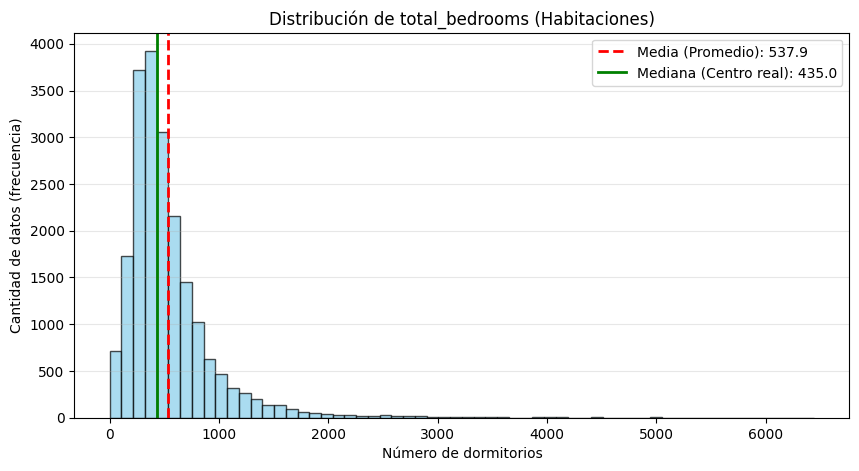

In [ ]:
import matplotlib.pyplot as plt

# Calculamos la media y la mediana
media = df["total_bedrooms"].mean()
mediana = df["total_bedrooms"].median()

# Creamos el Histograma
plt.figure(figsize=(10, 5))
plt.hist(
    df["total_bedrooms"].dropna(),
    bins=60,
    color="skyblue",
    edgecolor="black",
    alpha=0.7,
)

# Dibujamos líneas para destacar la diferencia entre Media y Mediana
plt.axvline(
    media,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media (Promedio): {media:.1f}",
)
plt.axvline(
    mediana,
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Mediana (Centro real): {mediana:.1f}",
)

# Títulos y leyenda
plt.title("Distribución de total_bedrooms (Habitaciones)")
plt.xlabel("Número de dormitorios")
plt.ylabel("Cantidad de datos (frecuencia)")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

## 2.3 Imputación por media

In [ ]:
media_bedrooms = df["total_bedrooms"].mean()

# Rellenamos las celdas vacías con esa media
df["total_bedrooms"] = df["total_bedrooms"].fillna(media_bedrooms)

# Verificamos que ya no queden datos vacíos.
print("Valores vacíos restantes:", df["total_bedrooms"].isnull().sum())

Valores vacíos restantes: 0


## 3.  La Mediana, el Héroe Silencioso


## 3.1 Cálculo de Robustez

**Enunciado:** Calcula la mediana de `population`. Explica por qué, si cortas el dataset por este valor, tendrías exactamente el 50 % de los datos a cada lado.


In [27]:
mediana_population = df["population"].median()

In [28]:
mediana_population

np.float64(1166.0)



Cortar el dataset por la mediana permite dividir los datos ordenados en dos mitades, ya que la mediana es, por definición estadística, el valor central (percentil 50) de una distribución.

Al ordenar los registros de menor a mayor, aproximadamente el **50 % de las observaciones queda por debajo de la mediana y el otro 50 % por encima**. Esta división depende de la posición de los datos ordenados, no de la magnitud de sus valores, por lo que la mediana es resistente a los valores extremos (*outliers*).

**Nota:** Si existen valores repetidos iguales a la mediana, las proporciones estrictas a cada lado pueden variar. Por eso, no siempre hay exactamente un 50 % de los datos estrictamente por debajo y otro 50 % estrictamente por encima.


## 3.2 Comparación directa


**Enunciado:** Compara la media y la mediana de `households`. Si la media es significativamente mayor que la mediana, ¿qué nos dice esto sobre la distribución de las familias? Crea un gráfico de densidad y muestra la media y la mediana mediante líneas verticales.


In [29]:
# Calculamos la media y la mediana
media_households = df["households"].mean()
mediana_households = df["households"].median()

print(f"Media de households: {media_households:.2f}")
print(f"Mediana de households: {mediana_households:.2f}")


Media de households: 499.54
Mediana de households: 409.00


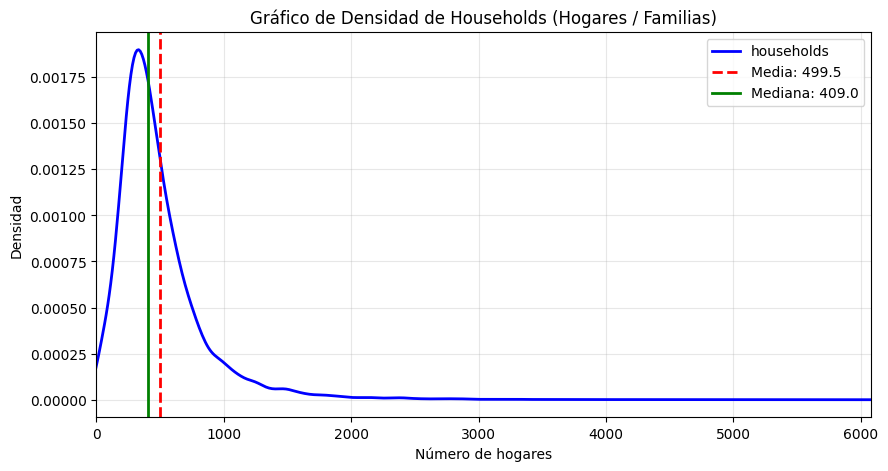

In [30]:
#  Creamos el gráfico de densidad
plt.figure(figsize=(10, 5))
df["households"].plot.kde(color="blue", linewidth=2)

# Dibujamos las líneas verticales para la media y la mediana
plt.axvline(
    media_households,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_households:.1f}",
)
plt.axvline(
    mediana_households,
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Mediana: {mediana_households:.1f}",
)

# Títulos y personalización
plt.title("Gráfico de Densidad de Households (Hogares / Familias)")
plt.xlabel("Número de hogares")
plt.ylabel("Densidad")
plt.xlim(
    0, df["households"].max()
)  # Para empezar el eje X en 0 y evitar números negativos
plt.legend()
plt.grid(alpha=0.3)

plt.show()


Si la media de `households` es significativamente mayor que la mediana, esto indica que la distribución presenta un **sesgo hacia la derecha (asimetría positiva)**.

La mayoría de los vecindarios tienen una cantidad de hogares relativamente baja o moderada, mientras que unos pocos presentan cantidades considerablemente mayores. Estos valores extremos elevan la media y hacen que sea superior a la mediana.

Por lo tanto, la **media puede no representar adecuadamente el número de hogares típico** de un vecindario, mientras que la mediana es una medida más robusta frente a los valores extremos y permite comprender mejor el centro de la distribución.


## 3.3 Imputación robusta


**Enunciado:** Si detectas que `total_bedrooms` tiene una cola larga (sesgo), ¿por qué se recomienda usar la mediana en lugar de la media para la imputación de valores faltantes (`NaN`)?



**Respuesta:** Se recomienda utilizar la **mediana** para rellenar los datos faltantes de `total_bedrooms`, ya que es una medida robusta que no se ve tan afectada por los valores extremos ni por la cola larga de la distribución.

Si utilizáramos la media, los valores excepcionalmente altos podrían elevar el promedio y hacer que asignáramos una cantidad de dormitorios poco representativa de los vecindarios comunes. En cambio, la mediana representa mejor el valor central de los datos y permite completar los valores faltantes sin verse tan afectada por esos extremos.


## 3.4 Variables ordinales


**Enunciado:**  Si crearas una nueva columna de rangos de precios (`Bajo`, `Medio`, `Alto`), ¿por qué la mediana sería más útil que la media para describir al "sujeto promedio?





**Respuesta:** La mediana es más útil porque no se deja distorsionar por las propiedades de lujo o precios extremadamente altos del mercado. En datos de vivienda e ingresos, la media suele dar una cifra inflada que la mayoría de las familias no alcanza, lo que haría que clasifiquemos mal los rangos (dejando a casi todos en el rango "Bajo"). En cambio, la mediana parte a la población exactamente en el punto medio (50 % por arriba y 50 % por abajo), garantizando que el rango "Medio" represente fielmente al comprador típico y a la realidad de la mayoría.



##  4. Distribuciones y Sesgos (Skewness)

## 4.1 Distribución normal


**Enunciado:** Grafica un histograma de `median_income`. Si la media, mediana y moda coinciden, ¿qué tipo de distribución enfrentamos y qué significa para un modelo lineal?


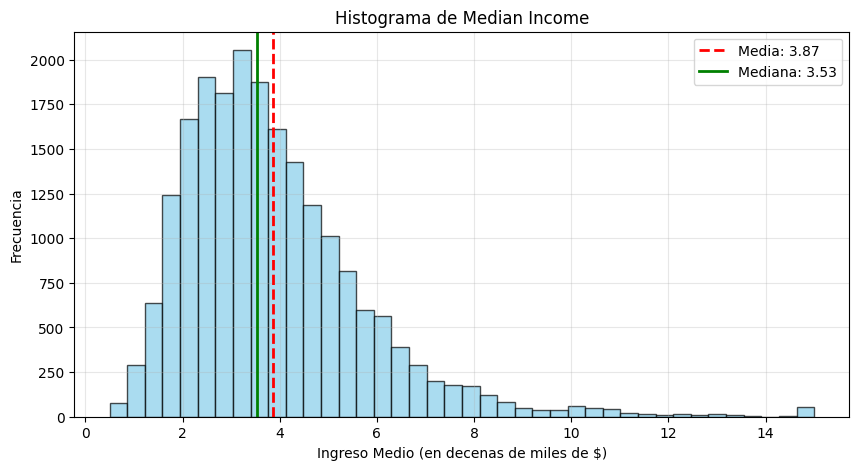

In [31]:
# Calculamos media y mediana
media_income = df["median_income"].mean()
mediana_income = df["median_income"].median()

# Graficamos el histograma
plt.figure(figsize=(10, 5))
plt.hist(
    df["median_income"],
    bins=40,
    color="skyblue",
    edgecolor="black",
    alpha=0.7,
)

# Dibujamos las líneas de media y mediana
plt.axvline(
    media_income,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_income:.2f}",
)
plt.axvline(
    mediana_income,
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Mediana: {mediana_income:.2f}",
)

plt.title("Histograma de Median Income")
plt.xlabel("Ingreso Medio (en decenas de miles de $)")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


Si la media, la mediana y la moda coinciden, nos enfrentamos a una **distribución normal** (o perfectamente simétrica), lo cual representa el **escenario ideal para un modelo lineal**, ya que estos modelos asumen la normalidad en los datos para garantizar predicciones estables y precisas. Pero como podemos ver en la gráfica, no coinciden exactamente, por lo que realmente enfrentamos una distribución con **sesgo a la derecha (asimetría positiva)**, donde los ingresos más altos de la población están arrastrando el promedio hacia arriba.


## 4.2 Sesgo a la derecha


**Enunciado:** Analiza la variable `total_rooms`. Si encuentras que Moda < Mediana < Media, ¿hacia dónde está sesgada la distribución?


In [32]:

moda_rooms = df["total_rooms"].mode()[0]
mediana_rooms = df["total_rooms"].median()
media_rooms = df["total_rooms"].mean()

print(f"Moda: {moda_rooms}")
print(f"Mediana: {mediana_rooms}")
print(f"Media: {media_rooms:.2f}")

Moda: 1527.0
Mediana: 2127.0
Media: 2635.76



Dado que se cumple la relación de **Moda (1527.0) < Mediana (2127.0) < Media (2635.76)**, la distribución de `total_rooms` está **sesgada hacia la derecha (asimetría positiva)**. Esto significa que la gran mayoría de las zonas tienen un número de habitaciones moderado o bajo, pero existen unas pocas zonas atípicas con un número exageradamente alto de habitaciones que terminan arrastrando la media hacia arriba.


## 4.3 Interpretación de Outliers


**Enunciado:** En una distribución con sesgo a la derecha, ¿quién es el responsable de "arrastrar" la media lejos del centro visual?



**Respuesta:** Los responsables de arrastrar la media lejos del centro visual son los **valores atípicos o extremos altos (*outliers* positivos)**. Como la media se calcula sumando todos los datos del grupo, unos pocos valores inusualmente grandes tienen el peso suficiente para inflar la suma total, empujando el promedio hacia la derecha y alejándolo de donde se concentra la verdadera mayoría de los datos.


## 4.4 Sesgo a la Izquierda


**Enunciado:** Si en una variable hipotética encontraras que Media < Mediana < Moda, ¿qué nos indicaría esto sobre los valores bajos del dataset?



**Respuesta:** Nos indicaría que existen **valores extremadamente bajos (datos atípicos u *outliers* bajos)** que están arrastrando la media hacia abajo. En esta situación, la gran mayoría de los datos se concentran en valores altos, pero unos pocos casos con cifras muy bajas estiran la "cola" hacia la izquierda y hacen que el promedio termine siendo menor que la mediana y la moda.


## 5. Aplicación Práctica de EDA

## 5.1 Analisis de la moda


**Enunciado:** Encuentra la moda de `ocean_proximity`. ¿En qué escenario de EDA es crucial conocer este valor, especialmente para datos categóricos?


In [33]:

moda_ocean = df["ocean_proximity"].mode()[0]

In [34]:
moda_ocean

'<1H OCEAN'


La moda de `ocean_proximity` es **`<1H OCEAN`**, y conocer este valor durante el EDA es crucial porque, al tratarse de una variable categórica, no es posible calcular la media ni la mediana, lo que convierte a la moda en la única medida de tendencia central disponible para imputar valores faltantes (`NaN`). Además, permite identificar la categoría dominante y detectar el grado de desbalance de clases en el dataset antes de realizar transformaciones para el modelado.


## 5.2 Detección de "Mentiras.Estadísticas:


**Enunciado:** El promedio de ingresos (`median_income`) en una zona parece muy alto, pero la mayoría de los residentes ganan poco. ¿Qué medida de tendencia central deberías reportar para "entender la realidad"?


**Respuesta:** Deberiamos reportar la **mediana**. Cuando la mayoría de los residentes gana poco pero unas pocas personas con ingresos altísimos inflan el promedio (la media), la distribución presenta un sesgo hacia la derecha. La media genera una "falsa realidad" de prosperidad porque es sensible a los valores extremos, mientras que la mediana representa con fidelidad al residente típico al situarse justo en el centro de los datos (50 % de la población gana menos y 50 % gana más), sin dejarse distorsionar por los ingresos atípicos de la zona.

## 5.3 Analisis de densidad


**Enunciado:** Utiliza Python para determinar en qué punto las tres medidas (Media, Mediana, Moda) caen en el mismo lugar. ¿Cómo se llama este escenario ideal?



**Respuesta:** El escenario ideal para que las tres medidas coincidan en el mismo lugar se denomina **distribución perfectamente simétrica (o distribución normal)**, donde el punto de cruce es el **centro exacto de la curva de densidad** (el pico más alto de la campana de Gauss). Dado que nuestro dataset real de viviendas de California presenta un sesgo hacia la derecha, generamos un conjunto de datos simétricos en Python para comprobar cómo las tres medidas coinciden en este caso ideal:


In [35]:
# Simulación de un escenario ideal hipotetico (Distribución Normal) 
import numpy as np
import scipy.stats as stats

# Generar 100,000 datos simétricos con centro en 100
datos_simetricos = np.random.normal(loc=100, scale=15, size=100000)

print(f"Media: {np.mean(datos_simetricos):.2f}")
print(f"Mediana: {np.median(datos_simetricos):.2f}")
print(f"Moda: {stats.mode(np.round(datos_simetricos))[0]:.2f}")

Media: 99.97
Mediana: 99.98
Moda: 102.00


Como se observa en la salida del script, al no existir sesgos ni valores atípicos que distorsionen los datos, las tres medidas convergen en el centro absoluto de la curva (100.00). Esto demuestra que, en una distribución simétrica ideal, la media, la mediana y la moda son equivalentes y cualquiera de ellas describe a la perfección la tendencia central del conjunto de datos.

## 5.4 Conclusión tecnica

**Enunciado:** Basándote en el comportamiento de median_house_value, justifica por escrito: ¿Es este dataset balanceado o requiere técnicas de normalización antes
de ser procesado por un modelo de ML?

**Respuesta:** El dataset **no está balanceado** y **sí necesita normalización** antes de usarlo en un modelo. Esto se debe a que los precios de las casas no están repartidos de forma pareja (la mayoría vale normal, pero unos pocos precios muy altos estiran los datos). Si le entregamos los números así de desordenados al modelo, se va a confundir con las diferencias tan grandes y dará malas predicciones, por lo que es necesario emparejar la escala de los datos primero.